# Task 4 — Random Forests and Ensembles
**Saduakas**

I print my Python and library versions first.

In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.14 2.3.4 2.3.3 1.7.2 3.10.7


I load the spam data. I keep one test set and use the same five folds for all model comparisons.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2345
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


My seed is **2345**. It is the last four digits of my student ID.

I set up the models from the task. The pipelines learn how to scale the data inside each training fold.

In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

## Part 1 — Bagging and out-of-bag estimates

I start with every row marked as out of bag. I mark the sampled rows as False.

In [4]:
def oob_mask(sample_indices, n_samples):
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

I count the votes from trees that did not see each row. I also compare the observed row shares with the formula.

In [5]:
bag.fit(X_train, y_train)
n_train = len(y_train)
votes = np.zeros((n_train, 2), dtype=int)
oob_shares = []
for estimator, sample in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(sample, n_train)
    oob_shares.append(mask.mean())
    rows = np.flatnonzero(mask)
    if rows.size:
        labels = estimator.predict(X_train[rows]).astype(int)
        votes[rows, labels] += 1

expected_oob = (1 - 1 / n_train) ** n_train
oob_share = np.mean(oob_shares)
print(f"Mean OOB share: {oob_share:.6f}; formula: {expected_oob:.6f}")
print(f"Mean in-bag share: {1 - oob_share:.6f}; formula: {1 - expected_oob:.6f}")
print(f"Manual OOB accuracy: {(votes.argmax(axis=1) == y_train).mean():.6f}")
print(f"sklearn OOB accuracy: {bag.oob_score_:.6f}")
print("Rows with no OOB votes:", (votes.sum(axis=1) == 0).sum())

Mean OOB share: 0.367964; formula: 0.367821
Mean in-bag share: 0.632036; formula: 0.632179
Manual OOB accuracy: 0.937203
sklearn OOB accuracy: 0.937203
Rows with no OOB votes: 0


I make a table for the five folds. I subtract scores fold by fold so that each pair uses the same rows.

In [6]:
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.model_selection import cross_validate, cross_val_predict

def cv_scores(model):
    return cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

def show_scores(results, prefix="Fold"):
    table = pd.DataFrame.from_dict(results, orient="index",
                                   columns=[f"{prefix} {i}" for i in range(1, 6)])
    table["Mean"] = [values.mean() for values in results.values()]
    table["Std"] = [values.std() for values in results.values()]
    display(table.round(6))

def compare(name, differences):
    mean = differences.mean()
    std = differences.std()
    if abs(mean) <= std:
        result = "The difference is inside the spread, so there is no clear winner."
    elif mean > 0:
        result = "The first value is higher by more than the spread."
    else:
        result = "The first value is lower by more than the spread."
    return f"**{name}** has mean {mean:+.4f} and std {std:.4f}. {result}"

scores = {name: cv_scores(model) for name, model in
          [("tree", tree), ("bag", bag), ("rf", rf), ("lr", lr), ("bag_lr", bag_lr)]}
bag_diffs = {"bag - tree": scores["bag"] - scores["tree"],
             "rf - tree": scores["rf"] - scores["tree"],
             "bag_lr - lr": scores["bag_lr"] - scores["lr"]}
show_scores({**scores, **bag_diffs})

rf.fit(X_train, y_train)
rf_accuracy = rf.score(X_test, y_test)
rf_se = np.sqrt(rf_accuracy * (1 - rf_accuracy) / len(y_test))
rf_mean, rf_std = scores["rf"].mean(), scores["rf"].std()
print(f"Forest OOB: {rf.oob_score_:.6f}; CV: {rf_mean:.6f}; test: {rf_accuracy:.6f}")
print(f"Test SE: {rf_se:.6f}")

Forest OOB: 0.949255; CV: 0.948308; test: 0.941009
Test SE: 0.007268


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
tree,0.896989,0.885895,0.882726,0.901587,0.914286,0.896297,0.011353
bag,0.938193,0.919176,0.925515,0.936508,0.952381,0.934355,0.011427
rf,0.936609,0.952456,0.941363,0.950794,0.960317,0.948308,0.008399
lr,0.931854,0.933439,0.935024,0.934921,0.938095,0.934667,0.002067
bag_lr,0.931854,0.935024,0.933439,0.936508,0.939683,0.935301,0.002686
bag - tree,0.041204,0.033281,0.042789,0.034921,0.038095,0.038058,0.003604
rf - tree,0.039620,0.066561,0.058637,0.049206,0.046032,0.052011,0.009516
bag_lr - lr,0.000000,0.001585,-0.001585,0.001587,0.001587,0.000635,0.001269


I use the paired differences to explain what bagging changed. I also check how close the three forest estimates are.

In [7]:
for name, difference in bag_diffs.items():
    display(Markdown(compare(name, difference)))
display(Markdown(
    "A single tree can change a lot when training rows change. Bagging votes "
    "across many trees, which reduces this effect. Logistic regression is usually "
    "more stable, so its bagged models can make very similar predictions."
))
gap = abs(rf.oob_score_ - rf_mean)
agreement = "agree" if gap <= rf_std else "do not agree"
display(Markdown(f"The forest OOB and CV scores {agreement} by the task rule. "
                 f"Their gap is {gap:.4f} and the fold std is {rf_std:.4f}."))
for name, score in [("OOB", rf.oob_score_), ("CV", rf_mean)]:
    gap = abs(score - rf_accuracy)
    relation = "within" if gap <= rf_se else "outside"
    display(Markdown(f"The {name} score is {gap:.4f} from the test score, "
                     f"which is {relation} one test standard error ({rf_se:.4f})."))

**bag - tree** has mean +0.0381 and std 0.0036. The first value is higher by more than the spread.

**rf - tree** has mean +0.0520 and std 0.0095. The first value is higher by more than the spread.

**bag_lr - lr** has mean +0.0006 and std 0.0013. The difference is inside the spread, so there is no clear winner.

A single tree can change a lot when training rows change. Bagging votes across many trees, which reduces this effect. Logistic regression is usually more stable, so its bagged models can make very similar predictions.

The forest OOB and CV scores agree by the task rule. Their gap is 0.0009 and the fold std is 0.0084.

The OOB score is 0.0082 from the test score, which is outside one test standard error (0.0073).

The CV score is 0.0073 from the test score, which is outside one test standard error (0.0073).

## Part 2 — Evaluating the filter

I choose the forest threshold using predictions from the training folds. I keep the largest threshold if recall is tied.

In [8]:
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, confusion_matrix)
import matplotlib.pyplot as plt

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr, recall, thresholds = roc_curve(y_train, oof, drop_intermediate=False)
valid = fpr <= 0.01
best_recall = recall[valid].max()
candidates = np.flatnonzero(valid & (recall == best_recall))
best_index = candidates[np.argmax(thresholds[candidates])]
threshold = thresholds[best_index]
print("Threshold:", float(threshold))
print(f"OOF FPR: {fpr[best_index]:.4%}; OOF recall: {recall[best_index]:.4%}")

Threshold: 0.75
OOF FPR: 0.9494%; OOF recall: 80.8274%


I draw both curves on the test set. I apply the saved threshold to the forest probabilities and count the mistakes.

Precision: 98.4802%; recall: 77.3270%; FPR: 0.7911%
The filter flagged 5 of 632 legitimate test mails.


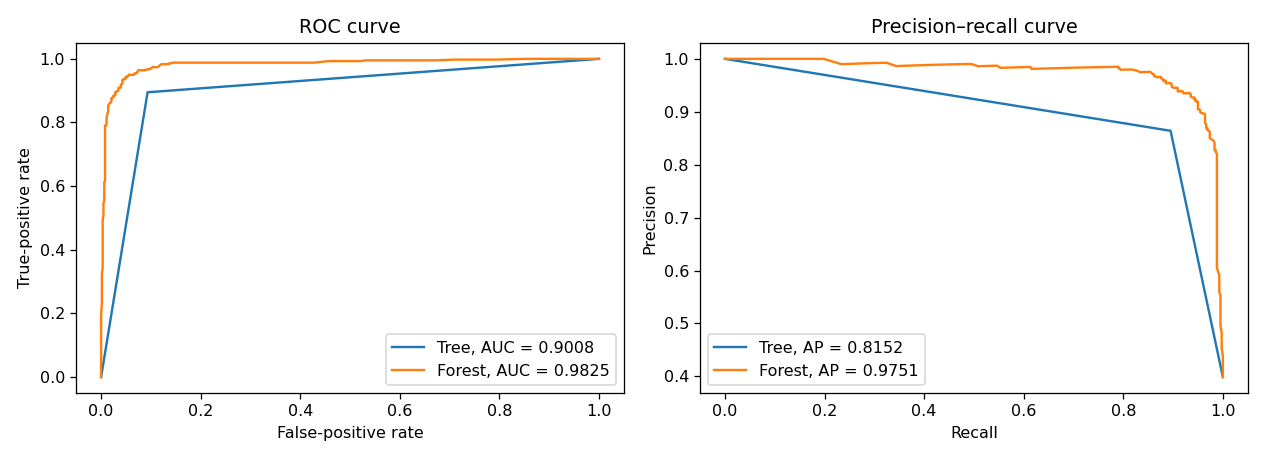

,Predicted legitimate,Predicted spam
Actual legitimate,627,5
Actual spam,95,324


The filter **met** the 1% target on the test split.

In [9]:
fitted_tree = clone(tree).fit(X_train, y_train)
forest_prob = rf.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, prob in [("Tree", fitted_tree.predict_proba(X_test)[:, 1]), ("Forest", forest_prob)]:
    curve_fpr, curve_tpr, _ = roc_curve(y_test, prob)
    curve_precision, curve_recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(curve_fpr, curve_tpr, label=f"{name}, AUC = {roc_auc_score(y_test, prob):.4f}")
    axes[1].plot(curve_recall, curve_precision,
                 label=f"{name}, AP = {average_precision_score(y_test, prob):.4f}")
axes[0].set(title="ROC curve", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].set(title="Precision–recall curve", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

matrix = confusion_matrix(y_test, forest_prob >= threshold, labels=[0, 1])
display(pd.DataFrame(matrix, index=["Actual legitimate", "Actual spam"],
                     columns=["Predicted legitimate", "Predicted spam"]))
tn, fp, fn, tp = matrix.ravel()
test_precision = tp / (tp + fp) if tp + fp else 0
test_recall = tp / (tp + fn)
test_fpr = fp / (tn + fp)
print(f"Precision: {test_precision:.4%}; recall: {test_recall:.4%}; FPR: {test_fpr:.4%}")
print(f"The filter flagged {fp} of {tn + fp} legitimate test mails.")
target_result = "met" if test_fpr <= 0.01 else "missed"
display(Markdown(f"The filter **{target_result}** the 1% target on the test split."))

I compare features used in good splits with features that change test accuracy when I shuffle them.

In [10]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10,
                              random_state=SEED, scoring="accuracy")
impurity = pd.Series(rf.feature_importances_, index=feature_names)
permutation = pd.Series(perm.importances_mean, index=feature_names)
display(impurity.nlargest(5).to_frame("Impurity importance"))
display(permutation.nlargest(5).to_frame("Permutation importance"))
imp_rank = impurity.rank(ascending=False, method="min")
perm_rank = permutation.rank(ascending=False, method="min")
top_features = impurity.nlargest(5).index.union(permutation.nlargest(5).index)
feature = (imp_rank - perm_rank).abs().loc[top_features].idxmax()
display(Markdown(f"**{feature}** is number {imp_rank[feature]:.0f} by impurity and "
                 f"number {perm_rank[feature]:.0f} by permutation. Impurity counts "
                 "how much this feature helps the tree splits during training. "
                 "Permutation measures how much test accuracy drops when I shuffle it. "
                 "Other features can give similar information, so these ranks can differ."))

,Impurity importance
char_freq_exclam,0.114799
char_freq_dollar,0.097156
word_freq_remove,0.073441
capital_run_length_average,0.066154
word_freq_free,0.064658


,Permutation importance
word_freq_remove,0.028449
word_freq_hp,0.017983
char_freq_exclam,0.011513
char_freq_dollar,0.006089
word_freq_you,0.004662


**word_freq_hp** is number 9 by impurity and number 2 by permutation. Impurity counts how much this feature helps the tree splits during training. Permutation measures how much test accuracy drops when I shuffle it. Other features can give similar information, so these ranks can differ.

## Part 3 — Voting

I add the weights in model order for each mail. If two labels have the same total, I keep the smaller label.

In [11]:
def hard_vote(predictions, weights=None):
    predictions = np.asarray(predictions)
    n_models, n_samples = predictions.shape
    if weights is None:
        weights = [1] * n_models
    answers = np.zeros(n_samples, dtype=int)
    for i in range(n_samples):
        counts = {0: 0}
        for model_index in range(n_models):
            label = int(predictions[model_index, i])
            counts[label] = counts.get(label, 0) + weights[model_index]
        answers[i] = max(counts, key=lambda label: (counts[label], -label))
    return answers

I check my votes against scikit-learn. I also count how often the members give different labels.

In [12]:
from itertools import combinations
from sklearn.ensemble import VotingClassifier

hard = VotingClassifier(members, voting="hard")
soft = VotingClassifier(members, voting="soft")
fitted_members = [(name, clone(model).fit(X_train, y_train)) for name, model in members]
member_labels = np.stack([model.predict(X_test) for name, model in fitted_members])
manual_labels = hard_vote(member_labels)
library_labels = clone(hard).fit(X_train, y_train).predict(X_test)
print(f"Hard vote agreement: {(manual_labels == library_labels).mean():.6f}")
disagreement = {}
for i, j in combinations(range(len(members)), 2):
    name = f"{members[i][0]} vs {members[j][0]}"
    disagreement[name] = (member_labels[i] != member_labels[j]).mean()
display(pd.Series(disagreement, name="Fraction of different labels").to_frame())

Hard vote agreement: 1.000000


,Fraction of different labels
lr vs knn,0.043768
lr vs tree,0.089439
knn vs tree,0.095147


I find the best member by its mean training CV score. Then I compare both voting models with that member.

In [13]:
voting_scores = {"lr": scores["lr"], "knn": cv_scores(knn), "tree": scores["tree"],
                 "hard": cv_scores(hard), "soft": cv_scores(soft)}
best_name = max((name for name, model in members), key=lambda name: voting_scores[name].mean())
best_scores = voting_scores[best_name]
print("Best member by CV mean:", best_name)
vote_diffs = {f"{name} - {best_name}": voting_scores[name] - best_scores for name in ("hard", "soft")}
show_scores({**voting_scores, **vote_diffs})
for name, difference in vote_diffs.items():
    display(Markdown(compare(name, difference)))

Best member by CV mean: lr


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
lr,0.931854,0.933439,0.935024,0.934921,0.938095,0.934667,0.002067
knn,0.906498,0.920761,0.917591,0.906349,0.922222,0.914684,0.006909
tree,0.896989,0.885895,0.882726,0.901587,0.914286,0.896297,0.011353
hard,0.923930,0.935024,0.931854,0.941270,0.941270,0.934670,0.006489
soft,0.931854,0.922345,0.919176,0.936508,0.944444,0.930866,0.009235
hard - lr,-0.007924,0.001585,-0.003170,0.006349,0.003175,0.000003,0.005015
soft - lr,0.000000,-0.011094,-0.015848,0.001587,0.006349,-0.003801,0.008304


**hard - lr** has mean +0.0000 and std 0.0050. The difference is inside the spread, so there is no clear winner.

**soft - lr** has mean -0.0038 and std 0.0083. The difference is inside the spread, so there is no clear winner.

## Part 4 — Stacking

I train the final model on three out-of-fold probability columns. Then I compare my result with scikit-learn.

In [14]:
from sklearn.ensemble import StackingClassifier

meta_train = np.column_stack([
    cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    for name, model in members
])
meta_test = np.column_stack([model.predict_proba(X_test)[:, 1] for name, model in fitted_members])
meta = LogisticRegression().fit(meta_train, y_train)
stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
print("OOF and test matrix shapes:", meta_train.shape, meta_test.shape)
print("Largest coefficient difference:", np.abs(meta.coef_ - stack.final_estimator_.coef_).max())
print("Same test predictions:", np.array_equal(meta.predict(meta_test), stack.predict(X_test)))
print(f"Manual test accuracy: {meta.score(meta_test, y_test):.6f}")
print(f"StackingClassifier test accuracy: {stack.score(X_test, y_test):.6f}")

OOF and test matrix shapes: (3153, 3) (1051, 3)
Largest coefficient difference: 0.0
Same test predictions: True
Manual test accuracy: 0.939106
StackingClassifier test accuracy: 0.939106


I fit a second final model with probabilities from the same rows used to train the members. I compare its weights and check stacking on the five folds.

In [15]:
naive_train = np.column_stack([model.predict_proba(X_train)[:, 1] for name, model in fitted_members])
naive = LogisticRegression().fit(naive_train, y_train)
coef_table = pd.DataFrame({"Naive": naive.coef_[0], "Out of fold": meta.coef_[0]},
                          index=[name for name, model in members])
display(coef_table.round(6))
display(Markdown(f"The tree weight is {coef_table.loc['tree', 'Naive']:.3f} in the naive fit "
                 f"and {coef_table.loc['tree', 'Out of fold']:.3f} in the OOF fit. "
                 "The tree can fit the labels of rows it sees. The naive final model sees "
                 "these easy predictions, while OOF predictions come from unseen rows."))
stack_scores = cv_scores(stack)
stack_diffs = {f"stack - {best_name}": stack_scores - best_scores,
               "stack - soft": stack_scores - voting_scores["soft"]}
show_scores({"stack": stack_scores, "soft": voting_scores["soft"],
             best_name: best_scores, **stack_diffs})
for name, difference in stack_diffs.items():
    display(Markdown(compare(name, difference)))

,Naive,Out of fold
lr,1.957432,4.013700
knn,1.816307,2.738947
tree,8.280055,1.391370


The tree weight is 8.280 in the naive fit and 1.391 in the OOF fit. The tree can fit the labels of rows it sees. The naive final model sees these easy predictions, while OOF predictions come from unseen rows.

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
stack,0.928685,0.931854,0.935024,0.944444,0.939683,0.935938,0.005595
soft,0.931854,0.922345,0.919176,0.936508,0.944444,0.930866,0.009235
lr,0.931854,0.933439,0.935024,0.934921,0.938095,0.934667,0.002067
stack - lr,-0.003170,-0.001585,0.000000,0.009524,0.001587,0.001271,0.004420
stack - soft,-0.003170,0.009509,0.015848,0.007937,-0.004762,0.005072,0.007857


**stack - lr** has mean +0.0013 and std 0.0044. The difference is inside the spread, so there is no clear winner.

**stack - soft** has mean +0.0051 and std 0.0079. The difference is inside the spread, so there is no clear winner.

## Part 5 — AdaBoost and label noise

I find the weighted error, update the weights of wrong answers, and divide by the new total.

In [16]:
import math

def adaboost_step(y_true, y_pred, weights):
    wrong = np.asarray(y_true) != np.asarray(y_pred)
    weights = np.array(weights, dtype=float, copy=True)
    error = weights[wrong].sum() / weights.sum()
    if error == 0:
        return math.inf, weights / weights.sum()
    alpha = math.log((1 - error) / error)
    weights[wrong] *= math.exp(alpha)
    return alpha, weights / weights.sum()

I use the three stumps from the lecture. I pass the new weights from each round into the next one.

In [17]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)
w = np.full(10, 0.1)
for round_number, prediction in enumerate([stump_1, stump_2, stump_3], start=1):
    error = w[prediction != y_toy].sum() / w.sum()
    alpha, w = adaboost_step(y_toy, prediction, w)
    print(f"Round {round_number}: error = {error:.4f}, alpha = {alpha:.4f}, weights = {w.round(4)}")
display(Markdown("Round 1 matches the slide check: error 0.300, alpha 0.847, "
                 "and weights about 0.071 for right answers and 0.167 for wrong answers. "
                 "In rounds 2 and 3, the error is about 0.214 and 0.182."))

Round 1: error = 0.3000, alpha = 0.8473, weights = [0.0714 0.0714 0.0714 0.0714 0.0714 0.0714 0.1667 0.1667 0.1667 0.0714]
Round 2: error = 0.2143, alpha = 1.2993, weights = [0.0455 0.0455 0.0455 0.1667 0.1667 0.1667 0.1061 0.1061 0.1061 0.0455]
Round 3: error = 0.1818, alpha = 1.5041, weights = [0.125  0.125  0.125  0.1019 0.1019 0.1019 0.0648 0.0648 0.0648 0.125 ]


Round 1 matches the slide check: error 0.300, alpha 0.847, and weights about 0.071 for right answers and 0.167 for wrong answers. In rounds 2 and 3, the error is about 0.214 and 0.182.

I repeat this update for the first five fitted stumps and compare my numbers with scikit-learn.

In [18]:
ada.fit(X_train, y_train)
w = np.full(n_train, 1 / n_train)
error_diffs, alpha_diffs = [], []
for i, stump in enumerate(ada.estimators_[:5]):
    prediction = stump.predict(X_train)
    error = w[prediction != y_train].sum() / w.sum()
    alpha, w = adaboost_step(y_train, prediction, w)
    error_diffs.append(abs(error - ada.estimator_errors_[i]))
    alpha_diffs.append(abs(alpha - ada.estimator_weights_[i]))
print("Largest error difference:", max(error_diffs))
print("Largest alpha difference:", max(alpha_diffs))

Largest error difference: 1.1102230246251565e-16
Largest alpha difference: 4.440892098500626e-16


I choose the round with the best mean validation accuracy. I use the first round if there is a tie. Then I compare the errors on the plot.

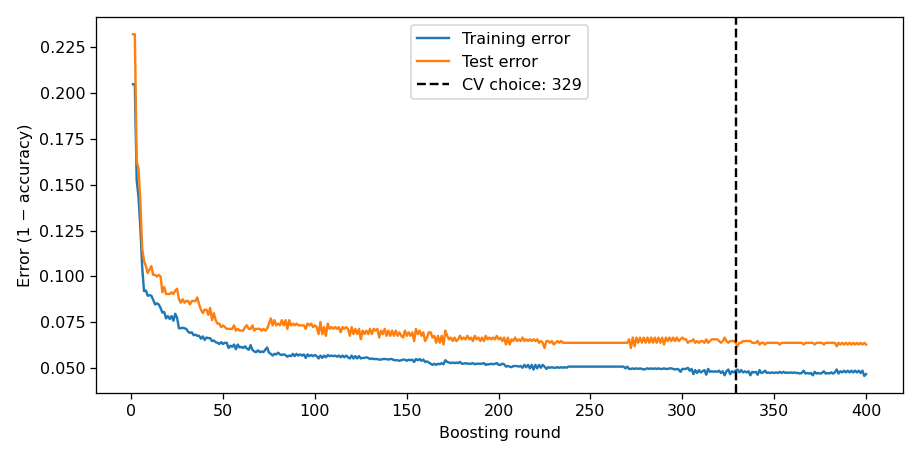

CV picks round **329**, with test error 6.3749%. The lowest test error is 6.0894% at round **225**. The gap is 0.2854%, which is at most one standard error (0.7536%).

In [19]:
validation_curves = []
for fit_rows, val_rows in cv.split(X_train, y_train):
    model = clone(ada).fit(X_train[fit_rows], y_train[fit_rows])
    validation_curves.append(list(model.staged_score(X_train[val_rows], y_train[val_rows])))
chosen_round = int(np.argmax(np.mean(validation_curves, axis=0))) + 1

train_error = 1 - np.array(list(ada.staged_score(X_train, y_train)))
test_error = 1 - np.array(list(ada.staged_score(X_test, y_test)))
rounds = np.arange(1, len(train_error) + 1)
plt.figure(figsize=(8, 4))
plt.plot(rounds, train_error, label="Training error")
plt.plot(rounds, test_error, label="Test error")
plt.axvline(chosen_round, color="black", linestyle="--", label=f"CV choice: {chosen_round}")
plt.xlabel("Boosting round")
plt.ylabel("Error (1 − accuracy)")
plt.legend()
plt.tight_layout()
plt.show()

test_best = int(test_error.argmin()) + 1
chosen_error = test_error[chosen_round - 1]
minimum_error = test_error[test_best - 1]
p = 1 - chosen_error
chosen_se = np.sqrt(p * (1 - p) / len(y_test))
relation = "more than" if chosen_error - minimum_error > chosen_se else "at most"
display(Markdown(f"CV picks round **{chosen_round}**, with test error {chosen_error:.4%}. "
                 f"The lowest test error is {minimum_error:.4%} at round **{test_best}**. "
                 f"The gap is {chosen_error - minimum_error:.4%}, which is {relation} "
                 f"one standard error ({chosen_se:.4%})."))

I flip 20% of the training labels five times. In each draw all three models see the same flipped rows. I keep the test labels clean.

In [20]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx

I measure the accuracy loss and follow the AdaBoost weights on the flipped rows.

In [21]:
ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}
clean = {name: clone(model).fit(X_train, y_train).score(X_test, y_test)
         for name, model in noise_models.items()}
noisy = {name: [] for name in noise_models}
weight_shares = []
for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    for name, model in noise_models.items():
        fitted = clone(model).fit(X_train, y_noisy)
        noisy[name].append(fitted.score(X_test, y_test))
        if name == "ada200":
            w = np.full(n_train, 1 / n_train)
            for stump in fitted.estimators_:
                _, w = adaboost_step(y_noisy, stump.predict(X_train), w)
            weight_shares.append((len(idx) / n_train, w[idx].sum()))

losses = {name: clean[name] - np.array(noisy[name]) for name in noise_models}
summary = []
for name in noise_models:
    summary.append([clean[name], np.mean(noisy[name]), np.std(noisy[name]),
                    losses[name].mean(), losses[name].std()])
display(pd.DataFrame(summary, index=list(noise_models), columns=[
    "Clean accuracy", "Noisy mean", "Noisy std", "Loss mean", "Loss std"]).round(6))
show_scores(losses, prefix="Draw")

shares = np.array(weight_shares)
display(pd.DataFrame(shares, index=range(1, 6), columns=["Before", "After"]).round(6))
print(f"Before mean ± std: {shares[:, 0].mean():.4%} ± {shares[:, 0].std():.4%}")
print(f"After mean ± std: {shares[:, 1].mean():.4%} ± {shares[:, 1].std():.4%}")

Before mean ± std: 20.0127% ± 0.0000%
After mean ± std: 39.6957% ± 0.6708%


,Clean accuracy,Noisy mean,Noisy std,Loss mean,Loss std
tree,0.901998,0.719315,0.014826,0.182683,0.014826
rf,0.941009,0.897050,0.005225,0.043958,0.005225
ada200,0.934348,0.906565,0.002911,0.027783,0.002911


,Draw 1,Draw 2,Draw 3,Draw 4,Draw 5,Mean,Std
tree,0.196004,0.183635,0.188392,0.191246,0.154139,0.182683,0.014826
rf,0.053283,0.037108,0.043768,0.042816,0.042816,0.043958,0.005225
ada200,0.028544,0.031399,0.022835,0.026641,0.029496,0.027783,0.002911


,Before,After
1,0.200127,0.390958
2,0.200127,0.387008
3,0.200127,0.402408
4,0.200127,0.403816
5,0.200127,0.400596


I compare the losses in pairs. I use the weight table to see how much attention AdaBoost gives the flipped rows.

In [22]:
noise_order = sorted(losses, key=lambda name: losses[name].mean(), reverse=True)
print("Largest mean loss:", noise_order[0])
for first, second in combinations(noise_order, 2):
    display(Markdown(compare(f"{first} loss - {second} loss", losses[first] - losses[second])))
display(Markdown(f"Flipped rows carry {shares[:, 0].mean():.1%} of the weight at first "
                 f"and {shares[:, 1].mean():.1%} after AdaBoost. "
                 "AdaBoost gives more weight to hard rows when its stumps get them wrong. "
                 "A deep tree can also fit wrong labels in small leaves, while a forest "
                 "averages the predictions of many trees trained on different samples."))

Largest mean loss: tree


**tree loss - rf loss** has mean +0.1387 and std 0.0138. The first value is higher by more than the spread.

**tree loss - ada200 loss** has mean +0.1549 and std 0.0161. The first value is higher by more than the spread.

**rf loss - ada200 loss** has mean +0.0162 and std 0.0065. The first value is higher by more than the spread.

Flipped rows carry 20.0% of the weight at first and 39.7% after AdaBoost. AdaBoost gives more weight to hard rows when its stumps get them wrong. A deep tree can also fit wrong labels in small leaves, while a forest averages the predictions of many trees trained on different samples.

## Part 6 — Recommendation and reproducibility

I use the test results at the fixed threshold and the paired CV results to explain my choice.

In [23]:
all_candidates = {**scores, **voting_scores, "stack": stack_scores}
inside = []
for name, values in all_candidates.items():
    difference = scores["rf"] - values
    if name != "rf" and abs(difference.mean()) <= difference.std():
        inside.append(name)
spread_sentence = (
    f"The forest's CV differences against {', '.join(inside)} are inside the fold spread."
    if inside else "None of the forest's CV differences against the other candidates is inside the fold spread."
)
verdict = ("I recommend the forest at this threshold for this dataset."
           if test_fpr <= 0.01 else
           "I would keep the forest as a candidate, but I would not deploy it under the 1% rule yet.")
display(Markdown(
    f"{verdict} The threshold is **{threshold}**, with OOF FPR {fpr[best_index]:.2%} "
    f"and OOF recall {best_recall:.2%}. On the test set it flags {fp} of {tn + fp} real mails "
    f"(FPR {test_fpr:.2%}) and catches {test_recall:.2%} of spam. "
    f"Test precision is {test_precision:.2%}, and the forest CV accuracy is {rf_mean:.2%}. "
    f"{spread_sentence}"
))

I recommend the forest at this threshold for this dataset. The threshold is **0.75**, with OOF FPR 0.95% and OOF recall 80.83%. On the test set it flags 5 of 632 real mails (FPR 0.79%) and catches 77.33% of spam. Test precision is 98.48%, and the forest CV accuracy is 94.83%. None of the forest's CV differences against the other candidates is inside the fold spread.

The seed and versions are at the top. I use the starter data and the pinned requirements. I save the notebook with its outputs after a fresh run.